# Multi-Asset Momentum Research

I investigated time-series momentum after observing that an earlier cross-sectional mean-reversion signal degraded during trending regimes. This project compares trend direction, volatility sizing, trading frequency, and shorting across SPY, TLT, GLD, USO, DBA, and UUP. Prices span 2010–2024; common evaluation dates are 2011-01-04 through 2024-12-31 after warm-up.

Run `python run_tsmom_research.py` to reproduce the calculations and this report. The cells below display the exported results; set `RECOMPUTE = True` to run the complete research pipeline from the notebook.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from tsmom.config import ResearchConfig
from tsmom.pipeline import run_research

ROOT = Path.cwd()
OUTPUT = ROOT / 'tsmom_results'
RECOMPUTE = False
if RECOMPUTE or not (OUTPUT / '10_all_comparisons.csv').exists():
    run_research(ResearchConfig(root=ROOT))

pd.set_option('display.max_columns', 20)
def show_table(name, indexed=True):
    table = pd.read_csv(OUTPUT / f'{name}.csv', index_col=0 if indexed else None)
    display(table.round(4))


## Daily versus weekly

Keep the signal, sizing, dates, and costs fixed. Weekly trading uses the first available session of each ISO week. The legacy row uses idealized close fills and weight-difference turnover.

In [2]:
show_table('01_daily_weekly', indexed=True)

,Net Sharpe,CAGR,Annual vol,Max drawdown,Gross Sharpe,Turnover / year,Costs / year,Financing drag / year,Mean gross exposure,Historical test Sharpe,Delta net Sharpe,Improves full-sample Sharpe
Legacy daily,0.6039,0.0225,0.0381,-0.0756,0.7717,21.4890,0.0064,0.0,0.5485,0.8036,0.0396,True
Daily next open,0.5642,0.0211,0.0383,-0.0939,0.7333,21.7471,0.0065,0.0,0.5485,0.7476,0.0000,False
Weekly next open,0.5031,0.0191,0.0391,-0.0848,0.5810,10.2641,0.0031,0.0,0.5458,0.7595,-0.0612,False


## Rebalancing bands

Bands are absolute portfolio-weight gaps, not price changes. Sign flips and exits override the band on scheduled trading days.

In [3]:
show_table('02_rebalancing_bands', indexed=True)

,Net Sharpe,CAGR,Annual vol,Max drawdown,Gross Sharpe,Turnover / year,Costs / year,Financing drag / year,Mean gross exposure,Historical test Sharpe,Delta net Sharpe,Improves full-sample Sharpe
Daily next open,0.5642,0.0211,0.0383,-0.0939,0.7333,21.7471,0.0065,0.0,0.5485,0.7476,0.0000,False
Weekly next open,0.5031,0.0191,0.0391,-0.0848,0.5810,10.2641,0.0031,0.0,0.5458,0.7595,-0.0612,False
Daily band 1.0%,0.5747,0.0216,0.0385,-0.0942,0.7347,20.6635,0.0061,0.0,0.5481,0.7509,0.0105,True
Daily band 2.5%,0.6140,0.0233,0.0387,-0.0907,0.7655,19.9602,0.0059,0.0,0.5468,0.8365,0.0498,True
Daily band 5.0%,0.6322,0.0238,0.0384,-0.0905,0.7629,17.4083,0.0050,0.0,0.5353,0.9242,0.0679,True
Weekly band 1.0%,0.5214,0.0198,0.0391,-0.0826,0.5967,9.9397,0.0030,0.0,0.5460,0.7803,-0.0428,False
Weekly band 2.5%,0.5495,0.0211,0.0395,-0.0824,0.6207,9.5863,0.0028,0.0,0.5451,0.8432,-0.0148,False
Weekly band 5.0%,0.4711,0.0174,0.0382,-0.0796,0.5359,8.6042,0.0025,0.0,0.5324,0.6440,-0.0932,False


## Signals and volatility

Compare slower 63/126/252-session momentum, bounded continuous signals, and EWMA volatility independently against the original daily strategy.

In [4]:
show_table('03_signal_volatility', indexed=True)

,Net Sharpe,CAGR,Annual vol,Max drawdown,Gross Sharpe,Turnover / year,Costs / year,Financing drag / year,Mean gross exposure,Historical test Sharpe,Delta net Sharpe,Improves full-sample Sharpe
Daily next open,0.5642,0.0211,0.0383,-0.0939,0.7333,21.7471,0.0065,0.0,0.5485,0.7476,0.0000,False
Slower ensemble daily,0.7182,0.0290,0.0410,-0.0778,0.8372,16.2076,0.0049,0.0,0.6340,0.8789,0.1539,True
Continuous ensemble daily,0.5159,0.0148,0.0293,-0.0559,0.6611,14.4532,0.0043,0.0,0.3980,0.7147,-0.0483,False
EWMA volatility daily,0.5591,0.0202,0.0371,-0.0962,0.7351,21.8990,0.0065,0.0,0.5412,0.7713,-0.0051,False


## Portfolio risk

The 10% asset scaling parameter does not target 10% portfolio volatility. The portfolio variant uses trailing covariance, a forecast floor, and exposure caps. Caps constrain target weights; holdings can drift between trades.

In [5]:
show_table('04_portfolio_risk', indexed=True)

,Net Sharpe,CAGR,Annual vol,Max drawdown,Gross Sharpe,Turnover / year,Costs / year,Financing drag / year,Mean gross exposure,Historical test Sharpe,Delta net Sharpe,Improves full-sample Sharpe
Daily next open,0.5642,0.0211,0.0383,-0.0939,0.7333,21.7471,0.0065,0.0,0.5485,0.7476,0.0000,False
Asset floor and caps,0.5571,0.0208,0.0382,-0.0939,0.7249,21.4591,0.0064,0.0,0.5432,0.7424,-0.0071,False
Portfolio vol daily,0.5781,0.0525,0.0965,-0.2087,0.7408,50.8762,0.0157,0.0,1.3000,0.7548,0.0139,True
Portfolio vol weekly,0.5442,0.0500,0.0986,-0.2113,0.6167,23.2755,0.0072,0.0,1.2961,0.8654,-0.0200,False


## Benchmarks

Isolate the effects of directional momentum, multiple horizons, and inverse-volatility sizing. The always-long benchmark differs from long-only momentum, which moves negative signals to cash.

,Net Sharpe,CAGR,Annual vol,Max drawdown,Gross Sharpe,Turnover / year,Costs / year,Financing drag / year,Mean gross exposure,Historical test Sharpe,Delta net Sharpe,Improves full-sample Sharpe
Daily next open,0.5642,0.0211,0.0383,-0.0939,0.7333,21.7471,0.0065,0.0,0.5485,0.7476,0.0000,False
Single horizon inverse vol,0.4554,0.0202,0.0463,-0.1211,0.5378,12.9452,0.0038,0.0,0.8446,0.7173,-0.1088,False
Ensemble without vol sizing,0.3319,0.0216,0.0722,-0.1671,0.4472,25.5589,0.0083,0.0,0.6318,0.4696,-0.2324,False
Long only inverse vol,0.7937,0.0329,0.0419,-0.0904,0.8154,3.0635,0.0009,0.0,0.8452,1.2753,0.2295,True
SPY buy and hold,0.8363,0.1361,0.1699,-0.3372,0.8364,0.0716,0.0000,0.0,1.0001,0.7497,0.2721,True


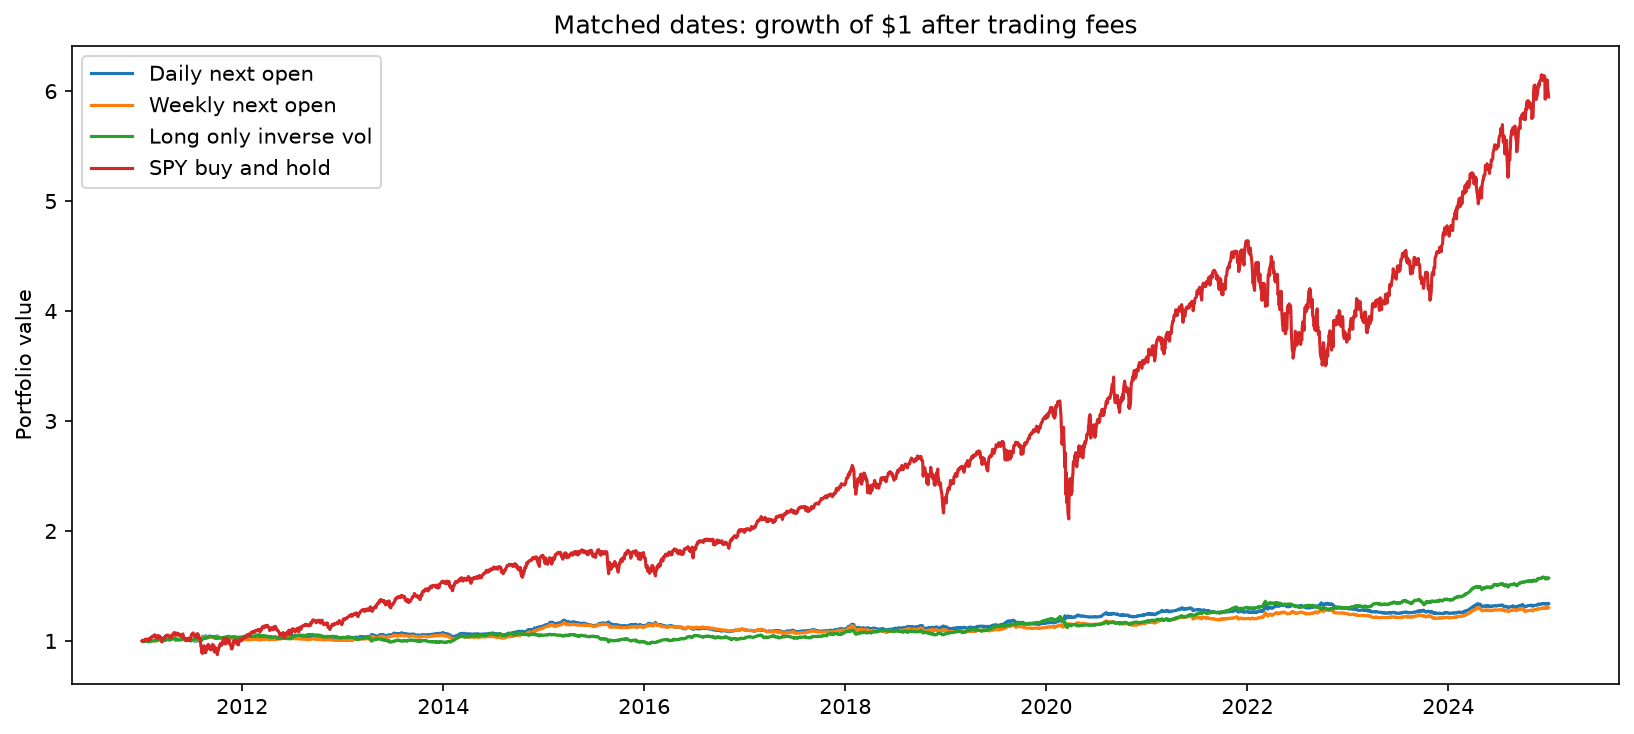

In [6]:
show_table('05_benchmarks', indexed=True)
display(Image(filename=str(OUTPUT / 'strategy_comparison.png')))

## Execution and funding

Next-open execution separates overnight old-position returns from intraday new-position returns. Same-close execution is optimistic. Fixed funding rates are illustrative rather than historical broker quotes.

In [7]:
show_table('06_execution_costs', indexed=True)

,Net Sharpe,CAGR,Annual vol,Max drawdown,Gross Sharpe,Turnover / year,Costs / year,Financing drag / year,Mean gross exposure,Historical test Sharpe,Delta net Sharpe,Improves full-sample Sharpe
Daily next open,0.5642,0.0211,0.0383,-0.0939,0.7333,21.7471,0.0065,0.0,0.5485,0.7476,0.0000,False
Weekly next open,0.5031,0.0191,0.0391,-0.0848,0.5810,10.2641,0.0031,0.0,0.5458,0.7595,-0.0612,False
Execution same_close,0.6022,0.0224,0.0381,-0.0757,0.7717,21.6660,0.0065,0.0,0.5485,0.8023,0.0379,True
Execution next_close,0.4716,0.0177,0.0389,-0.1025,0.6388,21.8044,0.0065,0.0,0.5485,0.5535,-0.0927,False
Daily double trading costs,0.3952,0.0145,0.0384,-0.1071,0.7334,21.7474,0.0130,0.0,0.5485,0.5940,-0.1691,False
Weekly double trading costs,0.4250,0.0160,0.0391,-0.0916,0.5810,10.2644,0.0061,0.0,0.5458,0.6908,-0.1392,False


## Funded long-only versus long/short

Both variants use 2% cash interest, 5% debit interest, and 1% short borrow. Excess Sharpe subtracts a fixed 2% risk-free rate. Negative weights are clipped to zero without reallocating the remaining weights. Restricted short proceeds earn no cash interest.

,CAGR,Annual vol,Max drawdown,Excess Sharpe vs 2% RF,Raw Sharpe (zero RF),2020–2024 excess Sharpe,Trading fees / year,Short borrow / year,Net cash interest / year,Mean long exposure,Mean short exposure
Always-long inverse vol,0.0353,0.0419,-0.0852,0.3774,0.8504,0.9342,0.0009,0.0000,0.0024,0.8452,-0.0000
Original long/short momentum,0.0324,0.0383,-0.0692,0.3352,0.8516,0.5328,0.0065,0.0020,0.0130,0.3494,0.1990
Original long-only momentum,0.0362,0.0265,-0.0323,0.6080,1.3542,0.8219,0.0034,0.0000,0.0130,0.3494,-0.0000
Slower long/short momentum,0.0390,0.0410,-0.0643,0.4701,0.9532,0.6447,0.0049,0.0023,0.0120,0.4015,0.2326
Slower long-only momentum,0.0427,0.0292,-0.0342,0.7684,1.4463,1.0407,0.0025,0.0000,0.0120,0.4015,-0.0000


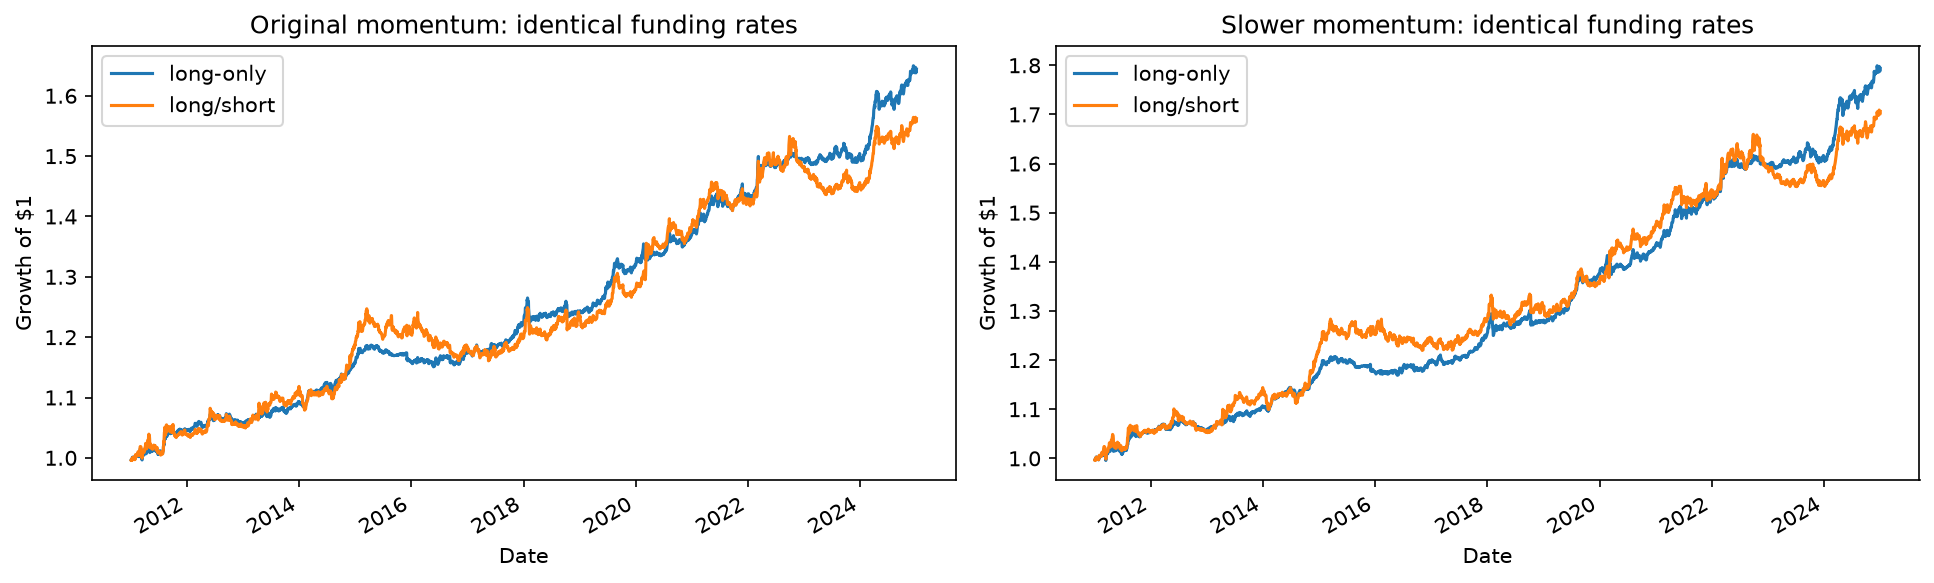

,Long/short minus long-only excess Sharpe,Shorting improved historical excess Sharpe
Ensemble,,
Original,-0.2728,False
Slower,-0.2983,False


,Ensemble,Annual short-borrow rate,Long-only excess Sharpe,Long/short excess Sharpe,Shorting excess Sharpe delta
0,Original,0.00,0.6080,0.3873,-0.2207
1,Original,0.01,0.6080,0.3352,-0.2728
2,Original,0.03,0.6080,0.2310,-0.3770
3,Slower,0.00,0.7684,0.5271,-0.2414
4,Slower,0.01,0.7684,0.4701,-0.2983
5,Slower,0.03,0.7684,0.3562,-0.4123


In [8]:
show_table('06b_funded_long_short', indexed=True)
display(Image(filename=str(OUTPUT / 'funded_direction.png')))
show_table('06b_shorting_increment')
show_table('06b_borrow_sensitivity', indexed=False)

## Historical walk-forward tests

Select among five predefined rules on trailing past returns, then freeze the rule for the next year. Tests restart from cash and charge entry and liquidation fees. Retrospective design and prior inspection mean these are historical diagnostics, not untouched OOS evidence.

,Net Sharpe,CAGR,Annual vol,Max drawdown
Past-only selected,0.5553,0.0218,0.0403,-0.0751
Daily reference with same annual resets,0.4527,0.0166,0.0380,-0.0828


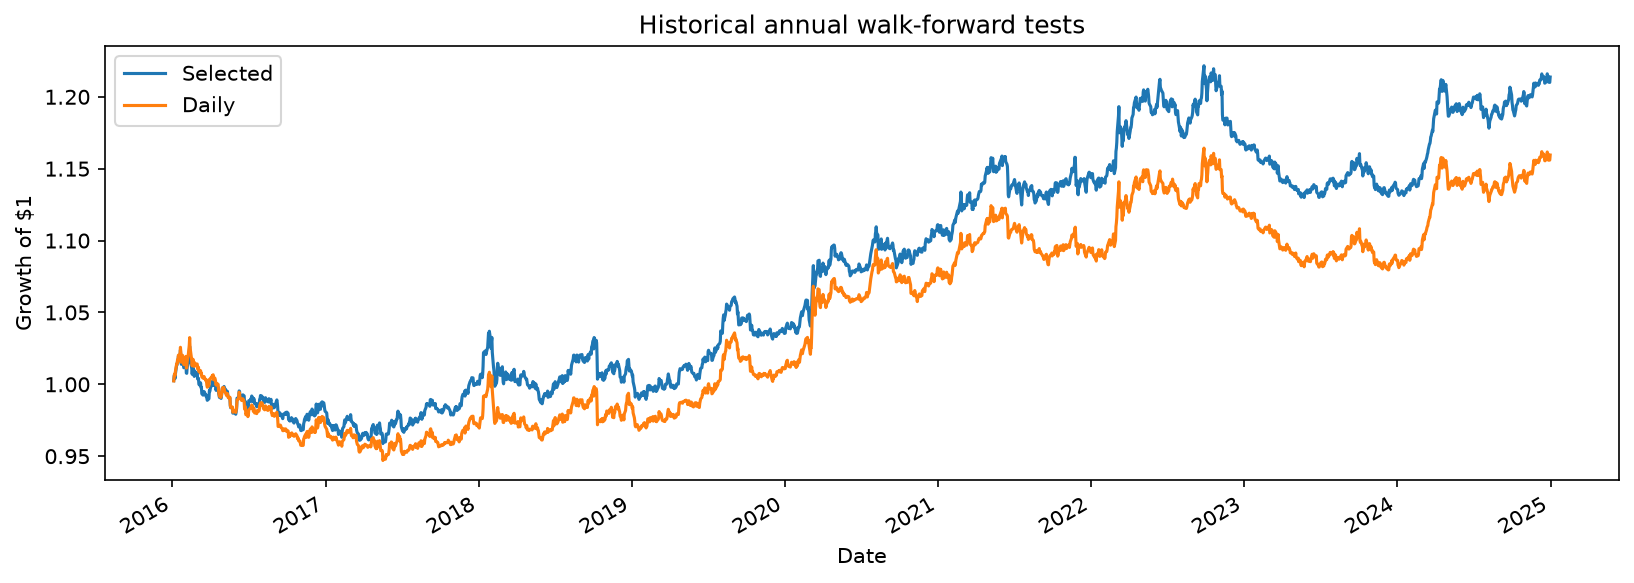

,Training start,Training end,Selected,Training Sharpe,Test Sharpe,Daily test Sharpe
Test year,,,,,,
2016,2011-01-04,2015-12-31,Slower daily,0.8603,-0.4644,-0.7767
2017,2012-01-01,2016-12-30,Slower daily,0.5830,0.6822,0.0445
2018,2013-01-01,2017-12-29,Slower daily,0.7719,0.1679,0.3560
2019,2014-01-01,2018-12-31,Slower daily,0.4461,0.7948,0.8396
2020,2015-01-01,2019-12-31,Slower daily,0.3285,1.5686,1.4310
2021,2016-01-01,2020-12-31,Slower daily,0.6137,0.6729,0.2805
2022,2017-01-01,2021-12-31,Slower daily,0.8766,0.4468,0.6044
2023,2018-01-01,2022-12-30,Daily band 2.5%,0.8842,-0.9475,-1.0780
2024,2019-01-01,2023-12-29,Daily band 2.5%,0.7005,2.0226,2.0160


In [9]:
show_table('07_walk_forward_performance', indexed=True)
display(Image(filename=str(OUTPUT / 'walk_forward.png')))
show_table('07_walk_forward_choices')

## Monte Carlo

Resample paired 2020–2024 returns and fees using 20/63/126-session moving blocks, 5,000 paths, and a three-year horizon. Probabilities depend on the historical sample and stationarity. Percentile Sharpe ranges are descriptive, not multiple-testing-adjusted significance tests.

,Rule,Block sessions,Cost multiplier,Loss probability (3y),Drawdown > 15% probability,CAGR p05,CAGR median,CAGR p95,Drawdown p05 (severe),Drawdown median,Longest drawdown p95 (sessions)
0,Daily next open,20,1,0.1040,0.0006,-0.0077,0.0275,0.0686,-0.0876,-0.0473,662.00
1,Daily next open,20,2,0.1656,0.0012,-0.0139,0.0213,0.0624,-0.0968,-0.0514,707.00
2,Daily next open,63,1,0.1620,0.0012,-0.0157,0.0239,0.0659,-0.0982,-0.0524,713.00
3,Daily next open,63,2,0.2326,0.0038,-0.0219,0.0177,0.0601,-0.1093,-0.0578,737.00
4,Daily next open,126,1,0.1816,0.0028,-0.0161,0.0217,0.0594,-0.1017,-0.0534,716.00
5,Daily next open,126,2,0.2548,0.0084,-0.0228,0.0155,0.0535,-0.1138,-0.0587,738.00
6,Weekly next open,20,1,0.0868,0.0004,-0.0061,0.0290,0.0665,-0.0853,-0.0470,642.05
7,Weekly next open,20,2,0.1106,0.0006,-0.0091,0.0260,0.0637,-0.0892,-0.0489,667.00
8,Weekly next open,63,1,0.1194,0.0004,-0.0099,0.0264,0.0659,-0.0878,-0.0479,680.05
9,Weekly next open,63,2,0.1444,0.0004,-0.0128,0.0236,0.0630,-0.0925,-0.0502,697.00


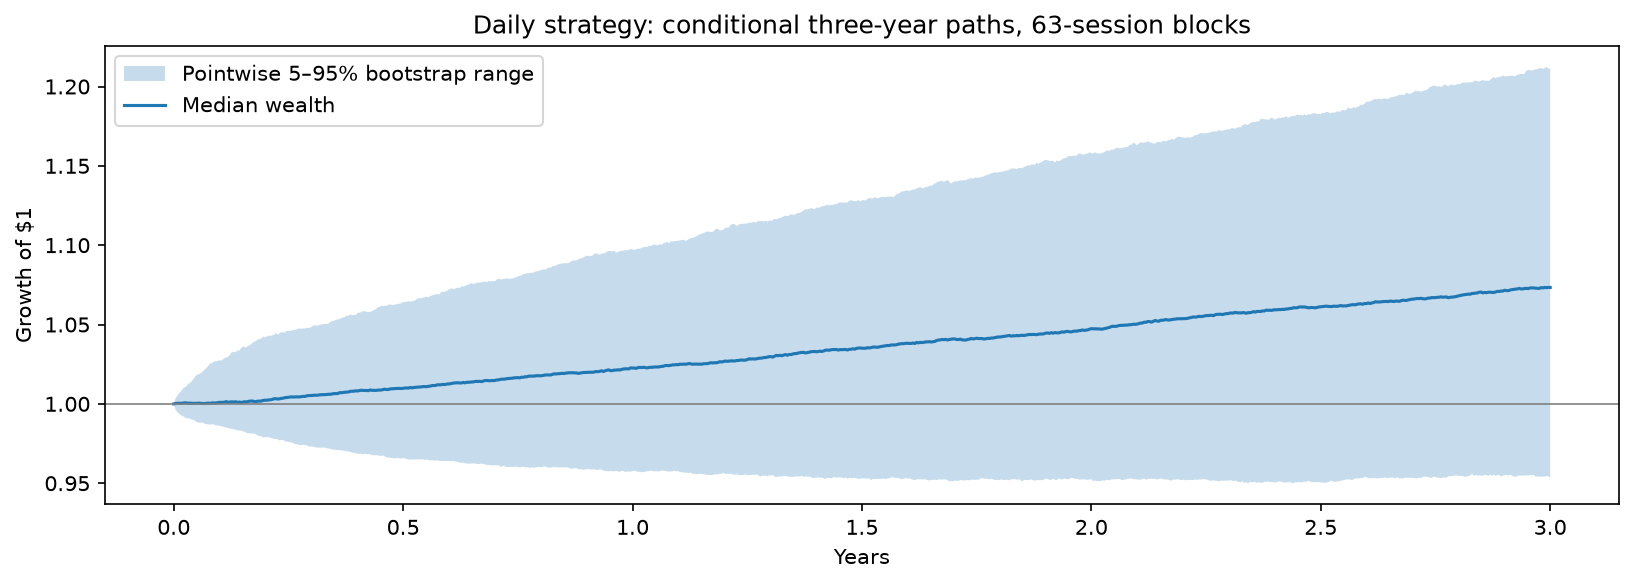

,Rule,Block sessions,Historical Sharpe,Bootstrap Sharpe p025,Bootstrap Sharpe median,Bootstrap Sharpe p975
0,Daily next open,20,0.7476,-0.1272,0.7190,1.5629
1,Daily next open,63,0.7476,-0.3221,0.6181,1.4857
2,Daily next open,126,0.7476,-0.3634,0.5632,1.3757
3,Weekly next open,20,0.7595,-0.0617,0.7255,1.5482
4,Weekly next open,63,0.7595,-0.1621,0.6570,1.4902
5,Weekly next open,126,0.7595,-0.1891,0.6724,1.4356


In [10]:
show_table('08_monte_carlo_summary', indexed=False)
display(Image(filename=str(OUTPUT / 'bootstrap_paths.png')))
show_table('08_sharpe_uncertainty', indexed=False)

## Full-strategy simulation

Jointly resample six-asset return rows and recalculate the strategy with 253 warm-up returns. Close-only synthetic prices use next-close execution. The 250 paths per block length are exploratory; block boundaries disrupt trends.

In [11]:
show_table('09_full_rule_mc_summary', indexed=False)

,Block sessions,Paths,Loss probability (3y),CAGR p05,CAGR median,Net Sharpe median,Drawdown p05 (severe),Annual fees median
0,126,250,0.272,-0.0219,0.0115,0.3256,-0.1045,0.0066
1,252,250,0.196,-0.0142,0.0151,0.4055,-0.0900,0.0066


## All fixed experiments

Full-sample rankings are descriptive. Zero-RF comparisons below omit financing; the funded direction table above uses a different Sharpe definition. No historical winner is automatically promoted as a live strategy.

In [12]:
show_table('10_all_comparisons', indexed=True)

,Net Sharpe,CAGR,Annual vol,Max drawdown,Gross Sharpe,Turnover / year,Costs / year,Financing drag / year,Mean gross exposure,Historical test Sharpe,Delta net Sharpe,Improves full-sample Sharpe
Legacy daily,0.6039,0.0225,0.0381,-0.0756,0.7717,21.4890,0.0064,0.0,0.5485,0.8036,0.0396,True
Daily next open,0.5642,0.0211,0.0383,-0.0939,0.7333,21.7471,0.0065,0.0,0.5485,0.7476,0.0000,False
Weekly next open,0.5031,0.0191,0.0391,-0.0848,0.5810,10.2641,0.0031,0.0,0.5458,0.7595,-0.0612,False
Daily band 1.0%,0.5747,0.0216,0.0385,-0.0942,0.7347,20.6635,0.0061,0.0,0.5481,0.7509,0.0105,True
Daily band 2.5%,0.6140,0.0233,0.0387,-0.0907,0.7655,19.9602,0.0059,0.0,0.5468,0.8365,0.0498,True
Daily band 5.0%,0.6322,0.0238,0.0384,-0.0905,0.7629,17.4083,0.0050,0.0,0.5353,0.9242,0.0679,True
Weekly band 1.0%,0.5214,0.0198,0.0391,-0.0826,0.5967,9.9397,0.0030,0.0,0.5460,0.7803,-0.0428,False
Weekly band 2.5%,0.5495,0.0211,0.0395,-0.0824,0.6207,9.5863,0.0028,0.0,0.5451,0.8432,-0.0148,False
Weekly band 5.0%,0.4711,0.0174,0.0382,-0.0796,0.5359,8.6042,0.0025,0.0,0.5324,0.6440,-0.0932,False
Slower ensemble daily,0.7182,0.0290,0.0410,-0.0778,0.8372,16.2076,0.0049,0.0,0.6340,0.8789,0.1539,True
